# 1. Знакомство с данными и EDA

Датасет [goodbooks-10k](https://www.kaggle.com/datasets/zygmunt/goodbooks-10k) содержит оценки пользователей Goodreads для 10 000 самых популярных книг.

В этом ноутбуке смотрим на данные и отвечаем на вопросы первого этапа: распределение оценок, активность пользователей,
популярность книг, теги и проблемы данных.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils import DATA_DIR

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## Загрузка данных

In [2]:
ratings = pd.read_csv(DATA_DIR / "ratings.csv")
books = pd.read_csv(DATA_DIR / "books.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")
book_tags = pd.read_csv(DATA_DIR / "book_tags.csv")

for name, df in [("ratings", ratings), ("books", books), ("tags", tags), ("book_tags", book_tags)]:
    print(f"{name:10s} {df.shape[0]:>8} строк, {df.shape[1]:>2} столбцов")

ratings      981756 строк,  3 столбцов
books         10000 строк, 23 столбцов
tags          34252 строк,  2 столбцов
book_tags    999912 строк,  3 столбцов


In [3]:
ratings.head()

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


In [4]:
books[["id", "book_id", "authors", "original_title", "title", "average_rating", "ratings_count"]].head()

,id,book_id,authors,original_title,title,average_rating,ratings_count
0,1,2767052,Suzanne Collins,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",4.34,4780653
1,2,3,"J.K. Rowling, Mary GrandPré",Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,4.44,4602479
2,3,41865,Stephenie Meyer,Twilight,"Twilight (Twilight, #1)",3.57,3866839
3,4,2657,Harper Lee,To Kill a Mockingbird,To Kill a Mockingbird,4.25,3198671
4,5,4671,F. Scott Fitzgerald,The Great Gatsby,The Great Gatsby,3.89,2683664


В `books.csv` два идентификатора. Столбец `id` (от 1 до 10 000) используется в `ratings.csv` как `book_id`,
а в столбце `book_id` лежит идентификатор Goodreads, по нему книги связаны с `book_tags.csv`.
Дальше в работе (в `utils.load_books`) эти столбцы переименованы в `book_id` и `goodreads_book_id`.

In [5]:
book_tags.head(3)

,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173


### Пропуски и дубликаты

In [6]:
print("Пропуски в ratings:", ratings.isna().sum().sum())
print("Пропуски в original_title:", books["original_title"].isna().sum())
print("Пропуски в title:", books["title"].isna().sum())

n_dup = ratings.duplicated(["user_id", "book_id"]).sum()
print(f"Повторов пары (user_id, book_id): {n_dup} ({n_dup / len(ratings):.2%})")
print("Строк с отрицательным count в book_tags:", (book_tags["count"] < 0).sum())

Пропуски в ratings: 0
Пропуски в original_title: 585
Пропуски в title: 0
Повторов пары (user_id, book_id): 2278 (0.23%)
Строк с отрицательным count в book_tags: 6


В оценках пропусков нет, но есть 2 278 повторов пары (пользователь, книга), это 0.23% строк.
Оставляем по одной оценке на пару. У 585 книг нет `original_title`, для них в контентной модели возьмём `title`.
В `book_tags` есть несколько строк с отрицательным счётчиком, их тоже отбрасываем.

In [7]:
ratings = ratings.drop_duplicates(["user_id", "book_id"], keep="last")
book_tags = book_tags[book_tags["count"] > 0]

n_users = ratings["user_id"].nunique()
n_books = ratings["book_id"].nunique()
print(f"Пользователей: {n_users}, книг: {n_books}, оценок: {len(ratings)}")

Пользователей: 53424, книг: 10000, оценок: 979478


## Распределение оценок

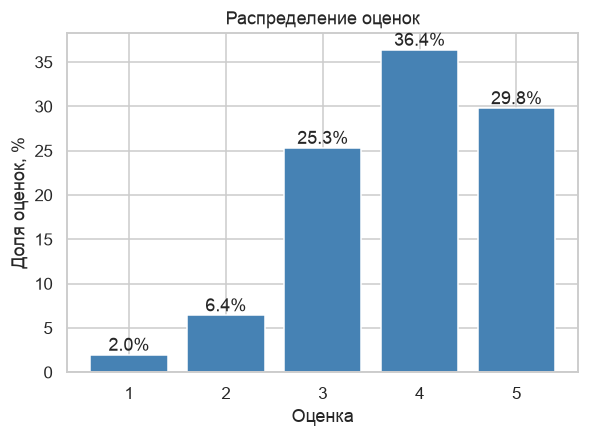

Средняя оценка: 3.86
Доля оценок 4 и 5: 66.2%


In [8]:
rating_share = ratings["rating"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(rating_share.index, rating_share.values * 100, color="steelblue")
ax.bar_label(bars, fmt="%.1f%%")
ax.set_xlabel("Оценка")
ax.set_ylabel("Доля оценок, %")
ax.set_title("Распределение оценок")
plt.show()

print(f"Средняя оценка: {ratings['rating'].mean():.2f}")
print(f"Доля оценок 4 и 5: {(ratings['rating'] >= 4).mean():.1%}")

Смещение в сторону высоких оценок есть. Две трети оценок приходятся на 4 и 5, средняя оценка 3.86, а единиц и двоек вместе меньше 9%.
Люди чаще дочитывают и оценивают то, что им понравилось, к тому же в датасет отобраны популярные книги.

Что из этого следует для дальнейшей работы:
- оценка 3 на деле скорее отрицательная, поэтому порог релевантности берём равным 4
- модель, которая всем предсказывает около 3.9, уже получит не очень большую ошибку, поэтому RMSE надо сравнивать с таким бейзлайном

## Активность пользователей

In [9]:
user_counts = ratings.groupby("user_id").size()
user_counts.describe().round(1)

count    53424.0
mean        18.3
std         26.2
min          1.0
25%          3.0
50%          8.0
75%         22.0
max        200.0
dtype: float64

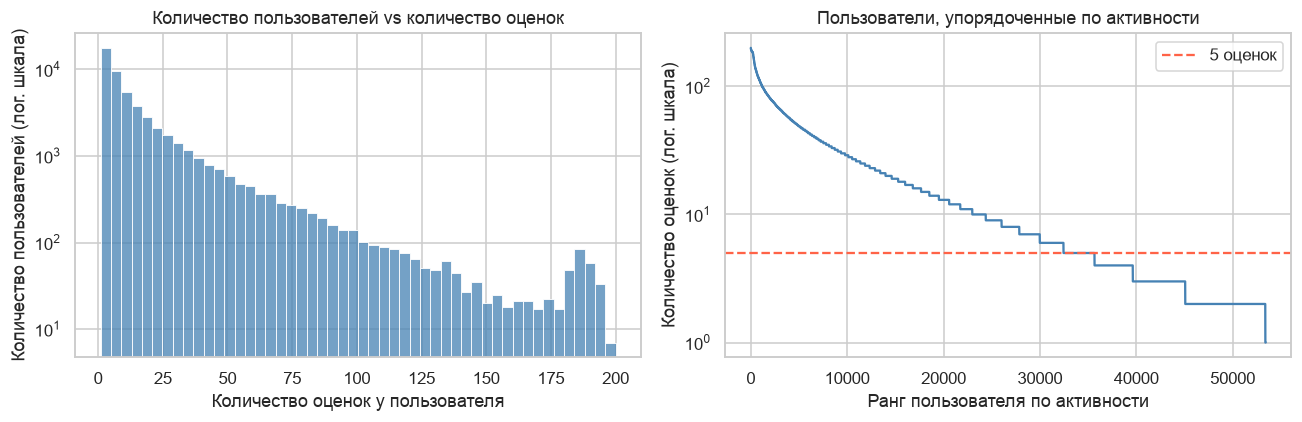

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(user_counts, bins=50, ax=axes[0], color="steelblue")
axes[0].set_yscale("log")
axes[0].set_xlabel("Количество оценок у пользователя")
axes[0].set_ylabel("Количество пользователей (лог. шкала)")
axes[0].set_title("Количество пользователей vs количество оценок")

sorted_counts = np.sort(user_counts.values)[::-1]
axes[1].plot(np.arange(1, len(sorted_counts) + 1), sorted_counts, color="steelblue")
axes[1].axhline(5, color="tomato", linestyle="--", label="5 оценок")
axes[1].set_yscale("log")
axes[1].set_xlabel("Ранг пользователя по активности")
axes[1].set_ylabel("Количество оценок (лог. шкала)")
axes[1].set_title("Пользователи, упорядоченные по активности")
axes[1].legend()

plt.tight_layout()
plt.show()

In [11]:
activity = pd.Series({
    "меньше 5 оценок": (user_counts < 5).mean(),
    "5-19 оценок": ((user_counts >= 5) & (user_counts < 20)).mean(),
    "20-99 оценок": ((user_counts >= 20) & (user_counts < 100)).mean(),
    "100 и больше": (user_counts >= 100).mean(),
})
print(activity.map("{:.1%}".format).to_string())

top10_share = user_counts.sort_values(ascending=False).head(n_users // 10).sum() / len(ratings)
print(f"\nНа 10% самых активных пользователей приходится {top10_share:.1%} всех оценок")

меньше 5 оценок    33.3%
5-19 оценок        39.4%
20-99 оценок       25.1%
100 и больше        2.2%

На 10% самых активных пользователей приходится 44.9% всех оценок


Распределение сильно скошено вправо. Медиана равна 8 оценкам, у трети пользователей их меньше пяти, а у 16% всего одна или две.
Активных пользователей (100 и больше оценок) около 2%, при этом 10% самых активных дают 45% всех оценок.

Пользователи с 1-4 оценками относятся к холодному старту. По такой истории коллаборативная модель почти ничего не узнает о вкусах.
Для них понадобится запасной вариант (популярное или контентные рекомендации).

## Популярность книг

In [12]:
book_counts = ratings.groupby("book_id").size()
book_counts.describe().round(1)

count    10000.0
mean        97.9
std          5.8
min          8.0
25%         99.0
50%        100.0
75%        100.0
max        100.0
dtype: float64

В этой версии датасета у каждой книги не больше 100 оценок. Файл `ratings.csv` является выборкой из Goodreads,
в которую попало примерно по сто оценок на книгу. Поэтому гистограмма по `ratings.csv` почти вырожденная.
Настоящую популярность книги показывает столбец `ratings_count` из `books.csv` (общее число оценок на Goodreads).
Построим оба графика.

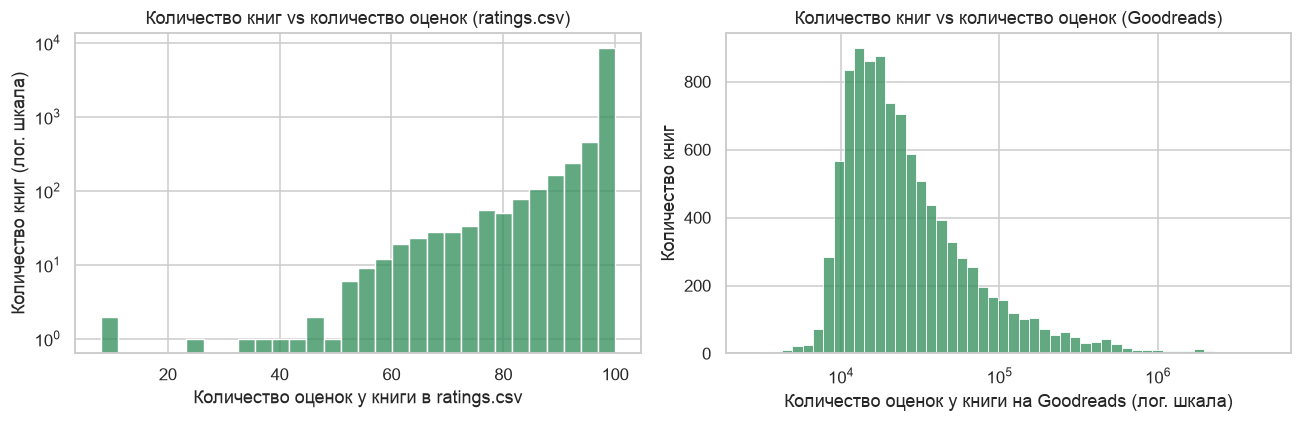

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(book_counts, bins=30, ax=axes[0], color="seagreen")
axes[0].set_yscale("log")
axes[0].set_xlabel("Количество оценок у книги в ratings.csv")
axes[0].set_ylabel("Количество книг (лог. шкала)")
axes[0].set_title("Количество книг vs количество оценок (ratings.csv)")

sns.histplot(books["ratings_count"], bins=50, log_scale=True, ax=axes[1], color="seagreen")
axes[1].set_xlabel("Количество оценок у книги на Goodreads (лог. шкала)")
axes[1].set_ylabel("Количество книг")
axes[1].set_title("Количество книг vs количество оценок (Goodreads)")

plt.tight_layout()
plt.show()

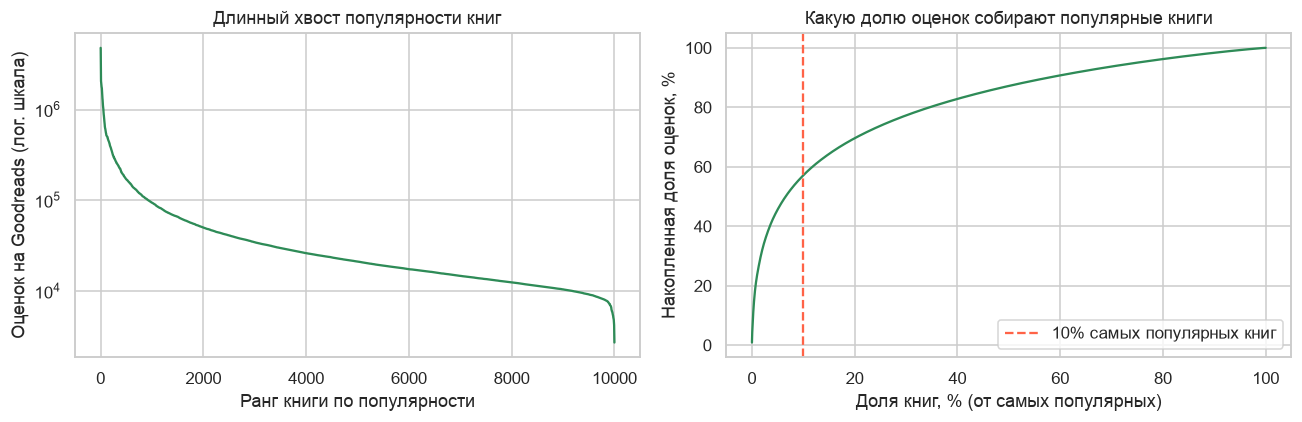

Топ-1% книг собирают 23.4% оценок на Goodreads
Топ-10% книг собирают 57.1% оценок на Goodreads
Топ-20% книг собирают 69.6% оценок на Goodreads


In [14]:
gr_counts = books["ratings_count"].sort_values(ascending=False).to_numpy()
cum_share = np.cumsum(gr_counts) / gr_counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(np.arange(1, len(gr_counts) + 1), gr_counts, color="seagreen")
axes[0].set_yscale("log")
axes[0].set_xlabel("Ранг книги по популярности")
axes[0].set_ylabel("Оценок на Goodreads (лог. шкала)")
axes[0].set_title("Длинный хвост популярности книг")

axes[1].plot(np.arange(1, len(gr_counts) + 1) / len(gr_counts) * 100, cum_share * 100, color="seagreen")
axes[1].axvline(10, color="tomato", linestyle="--", label="10% самых популярных книг")
axes[1].set_xlabel("Доля книг, % (от самых популярных)")
axes[1].set_ylabel("Накопленная доля оценок, %")
axes[1].set_title("Какую долю оценок собирают популярные книги")
axes[1].legend()

plt.tight_layout()
plt.show()

for share in (0.01, 0.1, 0.2):
    print(f"Топ-{share:.0%} книг собирают {cum_share[int(len(gr_counts) * share) - 1]:.1%} оценок на Goodreads")

In [15]:
books.nlargest(10, "ratings_count")[["title", "authors", "average_rating", "ratings_count"]]

,title,authors,average_rating,ratings_count
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4.34,4780653
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4.44,4602479
2,"Twilight (Twilight, #1)",Stephenie Meyer,3.57,3866839
3,To Kill a Mockingbird,Harper Lee,4.25,3198671
4,The Great Gatsby,F. Scott Fitzgerald,3.89,2683664
5,The Fault in Our Stars,John Green,4.26,2346404
6,The Hobbit,J.R.R. Tolkien,4.25,2071616
7,The Catcher in the Rye,J.D. Salinger,3.79,2044241
9,Pride and Prejudice,Jane Austen,4.24,2035490
8,"Angels & Demons (Robert Langdon, #1)",Dan Brown,3.85,2001311


По данным Goodreads длинный хвост виден хорошо. У "Голодных игр", "Гарри Поттера" и "Сумерек" от 3.9 до 4.8 млн оценок,
а у медианной книги около 21 тысячи. 1% самых популярных книг собирает 23% всех оценок, а 10% собирают 57%.
И это при том, что в датасет уже отобраны только 10 000 самых популярных книг.

В самом `ratings.csv` этого перекоса нет, почти у 80% книг 99-100 оценок. Из-за этого рекомендации по популярности
здесь не смогут опереться на число оценок. К этому вернёмся при оценке моделей.

## Теги

In [16]:
tag_totals = (
    book_tags.merge(tags, on="tag_id")
    .groupby("tag_name")
    .agg(total_count=("count", "sum"), n_books=("goodreads_book_id", "nunique"))
    .sort_values("total_count", ascending=False)
)
print(f"Всего тегов: {len(tags)}, из них используется: {len(tag_totals)}")
print(f"Тегов на книгу: {book_tags.groupby('goodreads_book_id').size().median():.0f} (медиана)")
tag_totals.head(10)

Всего тегов: 34252, из них используется: 34250
Тегов на книгу: 100 (медиана)


,total_count,n_books
tag_name,,
to-read,140718761,9983
currently-reading,7507958,9776
favorites,4503173,9881
fiction,3688819,9097
fantasy,3548157,4259
young-adult,1848306,3630
classics,1756920,2785
books-i-own,1317235,9799
romance,1231926,4251


На Goodreads теги ставят сами пользователи, по сути это их книжные полки. Среди самых частых много служебных,
которые описывают отношение читателя к книге: `to-read`, `currently-reading`, `favorites`, `owned` и т. п.
Тег `to-read` стоит почти у всех книг и по счётчику на порядок обгоняет остальные. Посмотрим топ отдельно с ними и без них.

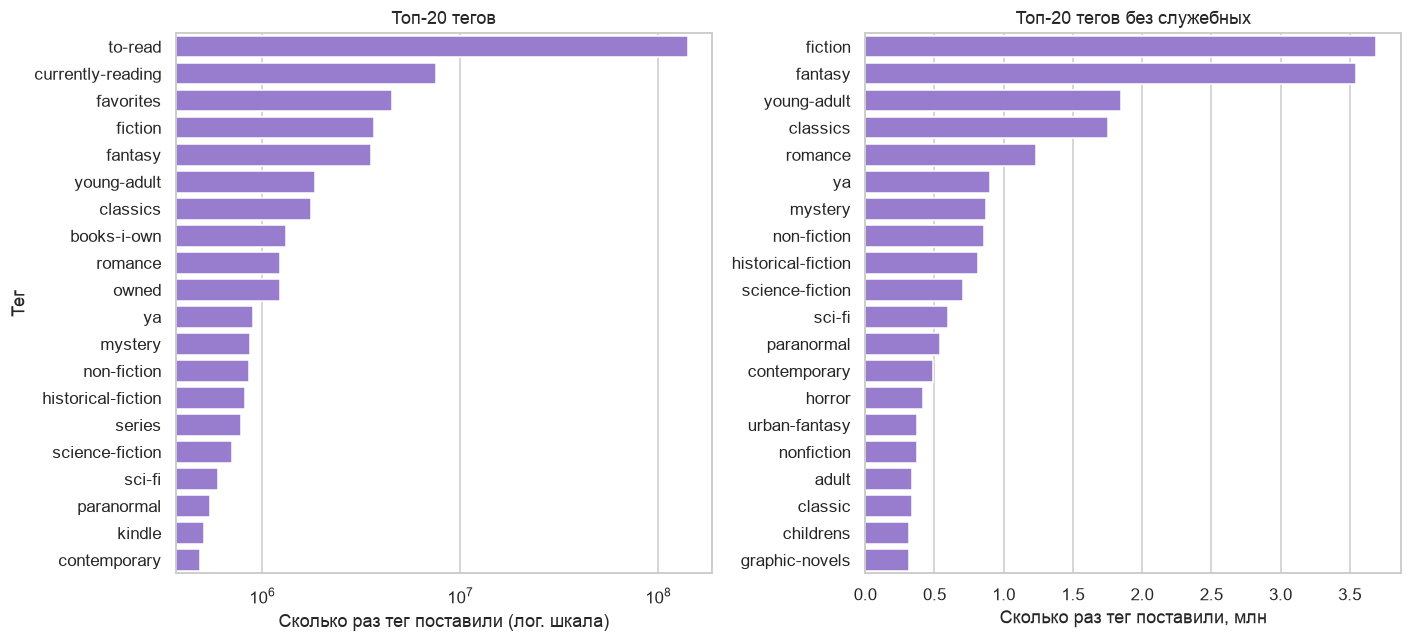

In [17]:
service_tags = {
    "to-read", "currently-reading", "favorites", "favourites", "owned", "books-i-own", "owned-books",
    "kindle", "library", "ebook", "ebooks", "my-books", "audiobook", "audiobooks", "audio", "default",
    "to-buy", "i-own", "my-library", "wish-list", "book-club", "series", "re-read", "all-time-favorites",
    "e-book", "e-books", "audible", "books", "have", "own-it", "favorite-books", "favorite", "read-in-2015",
    "read-in-2016", "read-in-2014", "read-in-2013", "5-stars", "my-favorites", "did-not-finish", "dnf",
    "abandoned", "library-books", "finished", "to-read-fiction", "home-library", "borrowed", "shelfari-favorites",
}
content_tags = tag_totals[~tag_totals.index.isin(service_tags)]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

top_all = tag_totals.head(20)
sns.barplot(x=top_all["total_count"], y=top_all.index, ax=axes[0], color="mediumpurple")
axes[0].set_xscale("log")
axes[0].set_xlabel("Сколько раз тег поставили (лог. шкала)")
axes[0].set_ylabel("Тег")
axes[0].set_title("Топ-20 тегов")

top_content = content_tags.head(20)
sns.barplot(x=top_content["total_count"] / 1e6, y=top_content.index, ax=axes[1], color="mediumpurple")
axes[1].set_xlabel("Сколько раз тег поставили, млн")
axes[1].set_ylabel("")
axes[1].set_title("Топ-20 тегов без служебных")

plt.tight_layout()
plt.show()

Если убрать служебные полки, остаются жанры: `fiction`, `fantasy`, `young-adult`, `classics`, `romance`, `mystery` и т. д.
Заметно, что один и тот же жанр записан по-разному (`young-adult` и `ya`, `science-fiction` и `sci-fi`, `non-fiction` и `nonfiction`).
Теги шумные, но жанровый сигнал в них есть, и контентная модель будет использовать именно его.
Служебные теги вроде `to-read` стоят почти у всех книг, поэтому TF-IDF сам даст им маленький вес.

## Разреженность матрицы пользователь-книга

In [18]:
density = len(ratings) / (n_users * n_books)
print(f"Размер матрицы: {n_users} x {n_books} = {n_users * n_books:,} ячеек")
print(f"Заполнено: {len(ratings):,} ({density:.3%})")
print(f"Разреженность: {1 - density:.3%}")

Размер матрицы: 53424 x 10000 = 534,240,000 ячеек
Заполнено: 979,478 (0.183%)
Разреженность: 99.817%


## Какие проблемы данных видны на этапе EDA

### Разреженность

Заполнено 0.18% матрицы пользователь-книга, в среднем пользователь оценил 18 книг из 10 000.
У двух случайных пользователей или книг общих оценок чаще всего нет совсем. Поэтому сходства в коллаборативной фильтрации
считаются по очень маленькому числу пересечений и получаются шумными. Хранить такую матрицу в плотном виде нет смысла
(534 млн ячеек), нужны разреженные форматы.

### Холодный старт

У трети пользователей меньше 5 оценок, у половины меньше 10. Для них персональные рекомендации
будут ненадёжными, а для совсем новых пользователей и книг коллаборативные методы не работают вообще.
Со стороны книг в этой выборке проблема сглажена искусственно (почти у всех книг по 100 оценок), но в реальном сервисе
новые книги появляются постоянно.

### Смещение популярности

По данным Goodreads 10% книг собирают 57% оценок. Модель, обученная на таких данных,
будет рекомендовать в основном бестселлеры, а книги из хвоста останутся без показов и без новых оценок.
В `ratings.csv` перекос убран при формировании выборки (не больше 100 оценок на книгу), поэтому здесь он проявится слабее,
чем в жизни. Перекос по пользователям при этом остался: 10% самых активных дают 45% оценок, и модели в первую очередь
подстраиваются под них.

### Смещение оценок

Оценки 4 и 5 составляют 66% всех оценок. Пользователи оценивают то, что сами выбрали и дочитали, поэтому пропуски
в матрице не случайны. Если оценки нет, то скорее всего книга человеку не интересна. Из-за этого модель, которая хорошо
предсказывает оценки на уже выбранных книгах, не обязательно хорошо выбирает книги из всего каталога.

### Качество данных

Есть повторы оценок, пропуски в названиях, шумные и дублирующие друг друга теги.
Временных меток нет, поэтому разбить данные по времени не получится, будем делать случайное разбиение.